In [1]:
import eu9_osm
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib_map_utils.core.scale_bar import scale_bar

In [2]:
# Params
lat, lon = 38.7105, -9.1385
radius = 850                         
crs = "EPSG:3763"

In [3]:
# OSM data
tags = {
    "building": True, "highway": True, "railway": True,
    "water": True, "natural": True, "landuse": True,
    "leisure": True, "amenity": True, "tourism": True,
    "historic": True, "shop": True, "public_transport": True,
    "man_made": True, "barrier": True, "place": True,
}
gdf = eu9_osm.features_from_point((lat, lon), tags=tags, dist=radius, shape="box").to_crs(crs)

In [4]:
# Map area
centre = gpd.GeoSeries([Point(lon, lat)], crs="EPSG:4326").to_crs(crs).iloc[0]
map_area = centre.buffer(radius, cap_style=3)
gdf = gpd.clip(gdf, map_area)

In [5]:
# Helper to select rows with relevant OSM tag
def tagged(column):
    if column not in gdf.columns:
        return pd.Series(False, index=gdf.index)
    return gdf[column].notna() & (gdf[column].astype(str) != "")

In [6]:
# Visual layers
polygon = gdf.geom_type.isin(["Polygon", "MultiPolygon"])
line = gdf.geom_type.isin(["LineString", "MultiLineString"])
point = gdf.geom_type.isin(["Point", "MultiPoint"])

buildings = gdf[tagged("building")]

roads = gdf[tagged("highway") & line]
major_types = ["motorway", "primary", "secondary", "tertiary", "primary_link", "tertiary_link"]
main_roads = roads[roads.highway.astype(str).isin(major_types)]
local_roads = roads.drop(main_roads.index)

railways = gdf[tagged("railway") & line]

natural_water = (gdf["natural"].isin(["water", "coastline", "bay", "strait"]) if "natural" in gdf.columns else pd.Series(False, index=gdf.index))
water_mask = polygon & (natural_water | tagged("water"))
water = gdf[water_mask].copy()

green = gdf[
    polygon
    & (
        gdf["natural"].isin(["wood", "grassland", "wetland"])
        | gdf["landuse"].isin(["grass", "flowerbed", "forest", "allotments"])
        | gdf["leisure"].isin(["garden", "playground", "park", "pitch", "dog_park"])
    )
    & ~water_mask
].copy()

trees = gdf[point & (gdf["natural"] =="tree")]

poi_columns = [c for c in ["amenity", "tourism", "historic", "shop", "public_transport", "place", "natural", "man_made", "barrier"] if c in gdf.columns]
pois = gdf[point & gdf[poi_columns].notna().any(axis=1) & ~(gdf["natural"] == "tree")] if poi_columns else gdf.iloc[0:0]

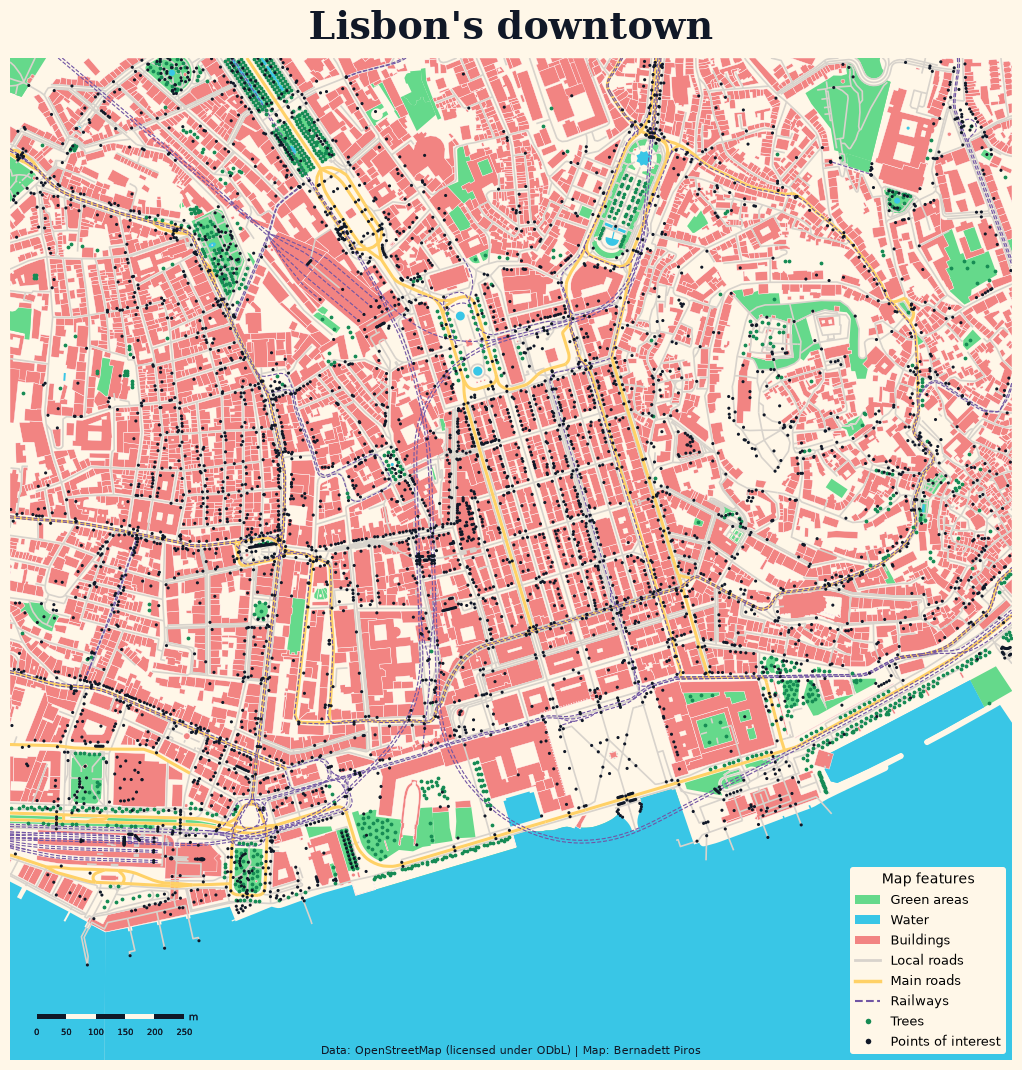

In [7]:
fig, ax = plt.subplots(figsize=(12, 12), facecolor="#FFF7E8")

# Layers
green.plot(ax=ax, color="#65D98B", ec="none", alpha=1, zorder=1)
water.plot(ax=ax, color="#39C6E6", ec="none", alpha=1, zorder=2)
buildings.plot(ax=ax, color="#F28482", ec="#FFFFFF", lw=0.3, alpha=1, zorder=3)
local_roads.plot(ax=ax, color="#D8D3CC", lw=1.2, zorder=4)
main_roads.plot(ax=ax, color="#FFD166", lw=2.2, zorder=5)
railways.plot(ax=ax, color="#7155A4", lw=0.8, linestyle="--", zorder=6)
trees.plot(ax=ax, color="#168B54", markersize=3, zorder=7)
pois.plot(ax=ax, color="#101827", markersize=5, ec="none", zorder=8)

# Map extent 
xmin, ymin, xmax, ymax = map_area.bounds
ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax))

ax.set_facecolor("#FFF7E8")
ax.set_aspect("equal")
ax.axis("off")

# Legend
legend_elements = [
    Patch(facecolor="#65D98B", label="Green areas"),
    Patch(facecolor="#39C6E6", label="Water"),
    Patch(facecolor="#F28482", label="Buildings"),
    Line2D([0], [0], color="#D8D3CC", lw=2, label="Local roads"),
    Line2D([0], [0], color="#FFD166", lw=2.5, label="Main roads"),
    Line2D([0], [0], color="#7155A4", lw=1.5, ls="--", label="Railways"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#168B54", markersize=4, markeredgecolor="none", label="Trees"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#101827", markersize=4, markeredgecolor="none", label="Points of interest")
]

ax.legend(handles=legend_elements, loc="lower right", title="Map features", fontsize=9, title_fontsize=10,
          frameon=True, facecolor="#FFF7E8", edgecolor="none", framealpha=1)

# Scale bar
scale_bar(ax=ax, location="lower left", style="boxes",
    bar={
        "projection": 3763,
        "unit": "m",
        "max": 250,
        "major_div": 5,
        "minor_type": "none",
        "height":0.05,
        "facecolors": ["#101827", "#FFF7E8"],
        "edgecolor": "none",        
        "edgewidth": 0
    },
    aob={
        "bbox_to_anchor": (0.01, 0.01),
        "bbox_transform": ax.transAxes
    },
    labels={
        "style": "major",
        "loc": "below",
        "fontsize": 6,
        "pad": 0
    },
    units={
        "loc": "bar"
    },
    text={
        "textcolor": "#101827",
        "stroke_color": "#101827",
        "stroke_width": 0.1,
        "fontsize": 7
    }
)

# Title
fig.text(0.5, 0.95, "Lisbon's downtown", color="#101827", size=27, weight="bold", fontfamily="serif", ha="center", va="top")

# Caption
fig.text(0.5, 0.08, 
         "Data: OpenStreetMap (licensed under ODbL) | Map: Bernadett Piros",
         size=8, color="#101827", ha="center")

plt.subplots_adjust(left=0.025, right=0.975, top=0.91, bottom=0.075)

plt.show()

# Save 
#fig.savefig("borgesian_downtown.png", bbox_inches="tight", pad_inches=0.2) 